# Marina Rihs Matos Wang


# Atividade Prática 4: Manipulação e Decisões de Visualização de Dados das IFES (1996–2026)



## Disciplina: Tecnologias para Data Science
## Professora: Carolina Ribeiro Xavier (CCOMP - UFSJ)


O código-fonte pode ser acessado publicamente no seguinte repositório do Git: https://github.com/MarinaWang11/Visualizacao_de_Dados_das_IFES.git

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

try:
    df = pd.read_csv('dados_investimento_e_vagas_ifes.csv')
    print(df.head())
    print(df.describe())
except Exception as e:
    print(f"Error loading CSV: {e}")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

    ano  investimento_total_ifes_bilhoes_brl  \
0  1996                                 32.1   
1  1997                                 31.8   
2  1998                                 30.5   
3  1999                                 29.8   
4  2000                                 31.2   

   investimento_assistencia_estudantil_bilhoes_brl  num_vagas_estudantes  \
0                                             0.02                342100   
1                                             0.02                351400   
2                                             0.03                362900   
3                                             0.03                375200   
4                                             0.04                391800   

   num_vagas_docente  num_vagas_tae  num_terceirizados  
0              26800          43100               8200  
1              27100          42800               8600  
2              27400          42100               9100  
3              27600      

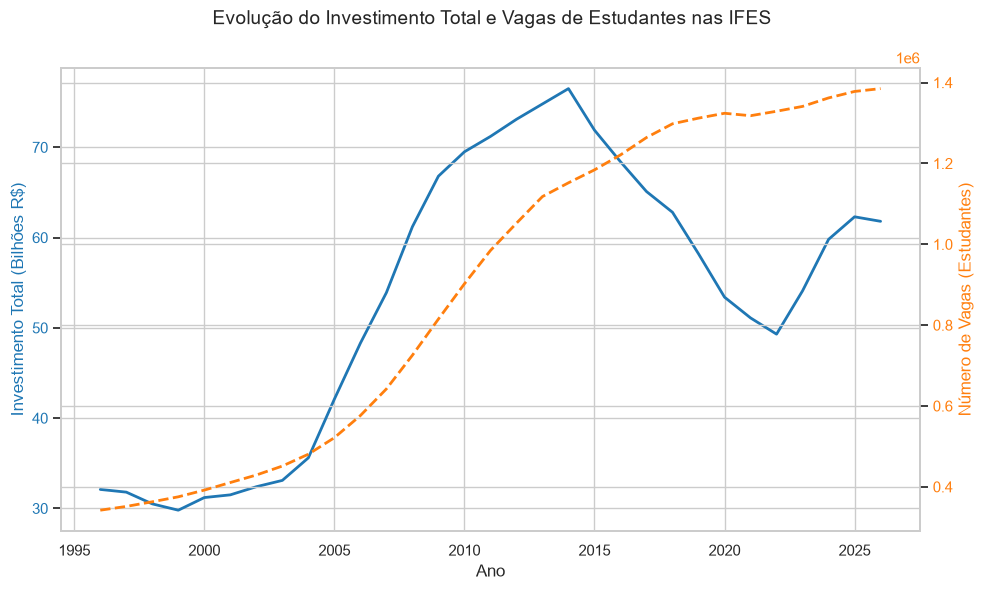

In [8]:
# 2. Evolução Temporal e Ajuste de Escalas

fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = 'tab:blue'
ax1.set_xlabel('Ano')
ax1.set_ylabel('Investimento Total (Bilhões R$)', color=color1)
ax1.plot(df['ano'], df['investimento_total_ifes_bilhoes_brl'], color=color1, linewidth=2, label='Investimento Total')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()  
color2 = 'tab:orange'
ax2.set_ylabel('Número de Vagas (Estudantes)', color=color2)  
ax2.plot(df['ano'], df['num_vagas_estudantes'], color=color2, linewidth=2, linestyle='--', label='Vagas Estudantes')
ax2.tick_params(axis='y', labelcolor=color2)

fig.suptitle('Evolução do Investimento Total e Vagas de Estudantes nas IFES', fontsize=14)
fig.tight_layout()  
plt.savefig('fig1_evolucao_escala.png', dpi=150)
plt.show()
plt.close()

### 2. Evolução Temporal e Ajuste de Escalas

* **O fato:** Historicamente, o investimento total e o número de vagas de estudantes acompanharam uma curva de crescimento simultâneo até o ano de 2014. No entanto, a partir de 2015, observa-se distanciamento e inversão de tendência: o orçamento total entra em acentuado declínio, enquanto o número de vagas continua crescendo e se estabiliza em um patamar superior a 1,3 milhão de estudantes, demonstrando uma expansão sem o devido lastro financeiro.
* **O design:** A utilização de um gráfico de linhas com duplo eixo Y é a melhor solução visual para contornar a enorme disparidade de escalas (valores financeiros na casa dos bilhões x vagas na casa dos milhares). Essa estrutura evita o achatamento da variável de menor ordem de grandeza e facilita a identificação temporal do ponto em que as tendências convergem (até 2014) e divergem (após 2015).

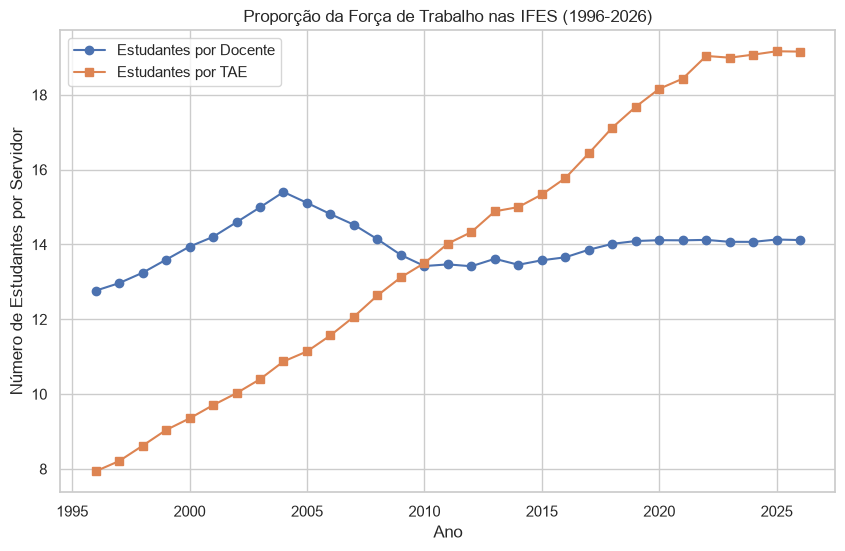

In [9]:
# 3. Análise de Proporção de Força de Trabalho

df['estudantes_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['estudantes_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

plt.figure(figsize=(10, 6))
plt.plot(df['ano'], df['estudantes_por_docente'], label='Estudantes por Docente', marker='o')
plt.plot(df['ano'], df['estudantes_por_tae'], label='Estudantes por TAE', marker='s')
plt.title('Proporção da Força de Trabalho nas IFES (1996-2026)')
plt.xlabel('Ano')
plt.ylabel('Número de Estudantes por Servidor')
plt.legend()
plt.savefig('fig2_proporcao.png', dpi=150)
plt.show()
plt.close()

### 3. Análise de Proporção de Força de Trabalho (Docentes vs. TAEs)

* **O fato:** A proporção de alunos por docente apresentou uma alta inicial, mas se estabilizou na casa de 14 alunos por professor a partir de 2010. Em contraste, a pressão sobre o quadro de Técnicos-Administrativos (TAEs) tem sido contínua e alarmante: a proporção saltou de menos de 8 alunos por TAE em 1996 para quase 20 alunos por TAE no final da série histórica.
* **O design:** Foi escolhido um gráfico de linhas conjuntas no mesmo eixo com marcadores geométricos distintos, pois ele é a representação mais clara para comparar a evolução concomitante de duas taxas com escalas similares. A plotagem em um único eixo garante a leitura do padrão histórico de divergência, enfatizando a diferença entre a estabilização de uma categoria e a sobrecarga da outra.

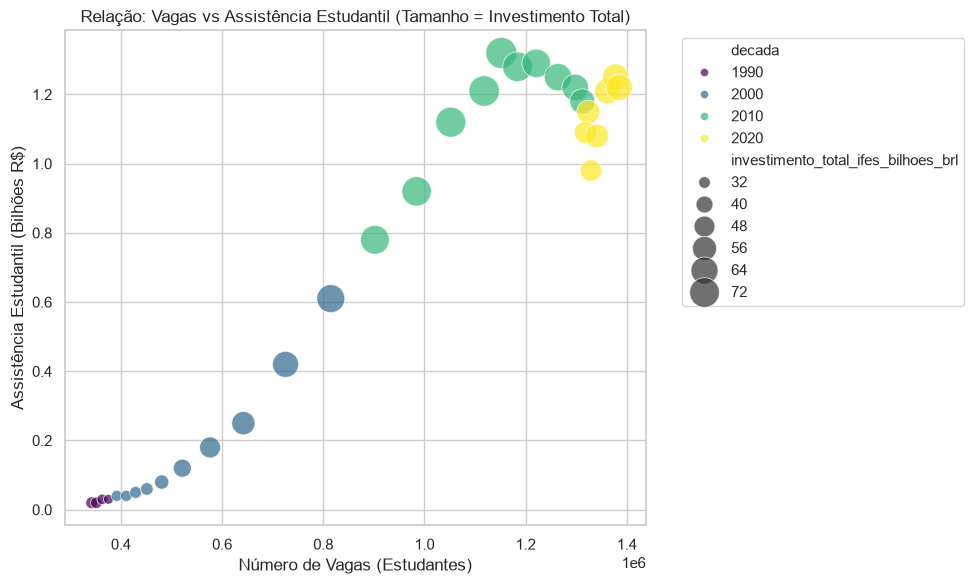

In [10]:
# 4. Correlação entre Fatores e Desempenho Orçamentário

df['decada'] = (df['ano'] // 10) * 10

df_agg = df.groupby('decada').agg({
    'investimento_assistencia_estudantil_bilhoes_brl': ['mean', 'sum'],
    'num_vagas_estudantes': ['mean', 'sum'],
    'investimento_total_ifes_bilhoes_brl': 'mean'
}).reset_index()

df_agg.columns = ['decada', 'assistencia_mean', 'assistencia_sum', 'vagas_mean', 'vagas_sum', 'investimento_total_mean']

plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(
    data=df, 
    x='num_vagas_estudantes', 
    y='investimento_assistencia_estudantil_bilhoes_brl', 
    size='investimento_total_ifes_bilhoes_brl',
    hue='decada',
    palette='viridis',
    sizes=(50, 500),
    alpha=0.7
)
plt.title('Relação: Vagas vs Assistência Estudantil (Tamanho = Investimento Total)')
plt.xlabel('Número de Vagas (Estudantes)')
plt.ylabel('Assistência Estudantil (Bilhões R$)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig3_correlacao.png', dpi=150)
plt.show()
plt.close()


### 4. Correlação entre Fatores e Desempenho Orçamentário

* **O fato:** O cruzamento dos dados agrupados por década revela que, nos anos 2000 e 2010, o aumento de vagas foi acompanhado proporcionalmente pelo aumento consistente do orçamento de assistência estudantil (trajetória ascendente no gráfico). Na década de 2020, o cenário muda drasticamente: há a manutenção de um alto número de vagas atrelada a uma queda progressiva tanto na assistência estudantil quanto nos investimentos totais das instituições.
* **O design:** Adotou-se o gráfico de dispersão com tamanho de ponto proporcional (*bubble chart*) por ser visualmente e analiticamente superior a um mapa de calor para este conjunto de dados. Ele permite cruzar três dimensões simultaneamente: o aumento de vagas (eixo X), o investimento em assistência (eixo Y) e o investimento total (tamanho da bolha). 

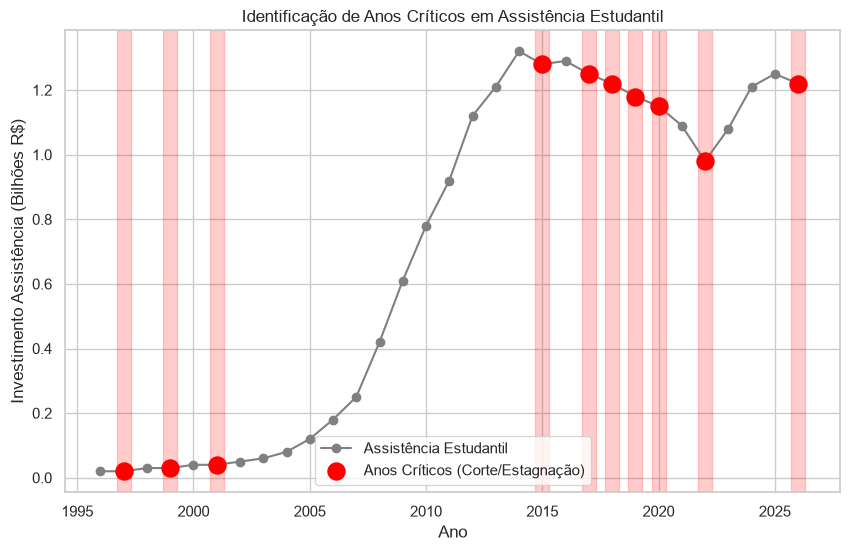

In [11]:

# 5. Filtragem Condicional de Anos Críticos

df['vagas_diff'] = df['num_vagas_estudantes'].diff()
df['assist_diff'] = df['investimento_assistencia_estudantil_bilhoes_brl'].diff()
criticos = df[(df['vagas_diff'] > 0) & (df['assist_diff'] <= 0)]

plt.figure(figsize=(10, 6))
plt.plot(df['ano'], df['investimento_assistencia_estudantil_bilhoes_brl'], label='Assistência Estudantil', color='gray', marker='o')
plt.scatter(criticos['ano'], criticos['investimento_assistencia_estudantil_bilhoes_brl'], color='red', s=150, label='Anos Críticos (Corte/Estagnação)', zorder=5)

for index, row in criticos.iterrows():
    plt.axvspan(row['ano']-0.3, row['ano']+0.3, color='red', alpha=0.2)

plt.title('Identificação de Anos Críticos em Assistência Estudantil')
plt.xlabel('Ano')
plt.ylabel('Investimento Assistência (Bilhões R$)')
plt.legend()
plt.savefig('fig4_criticos.png', dpi=150)
plt.show()
plt.close()


### 5. Filtragem Condicional de Anos Críticos

* **O fato:** A filtragem denuncia que os cenários mais severos — caracterizados pelo aumento de matrículas ocorrendo simultaneamente a cortes ou estagnação na assistência estudantil — concentram-se na segunda metade do recorte histórico. Isso evidencia uma crise de permanência, onde mais estudantes entram no sistema enquanto a rede de apoio financeiro é retraída.
* **O design:** A estratégia na linha do tempo utilizou marcadores circulares vermelhos e sombreamento de fundo vertical (*span*). Essa decisão direciona a leitura para os anos críticos, utilizando a cor vermelha como alerta natural, enquanto a linha contínua cinza mantém o contexto da tendência global, evitando poluição visual.

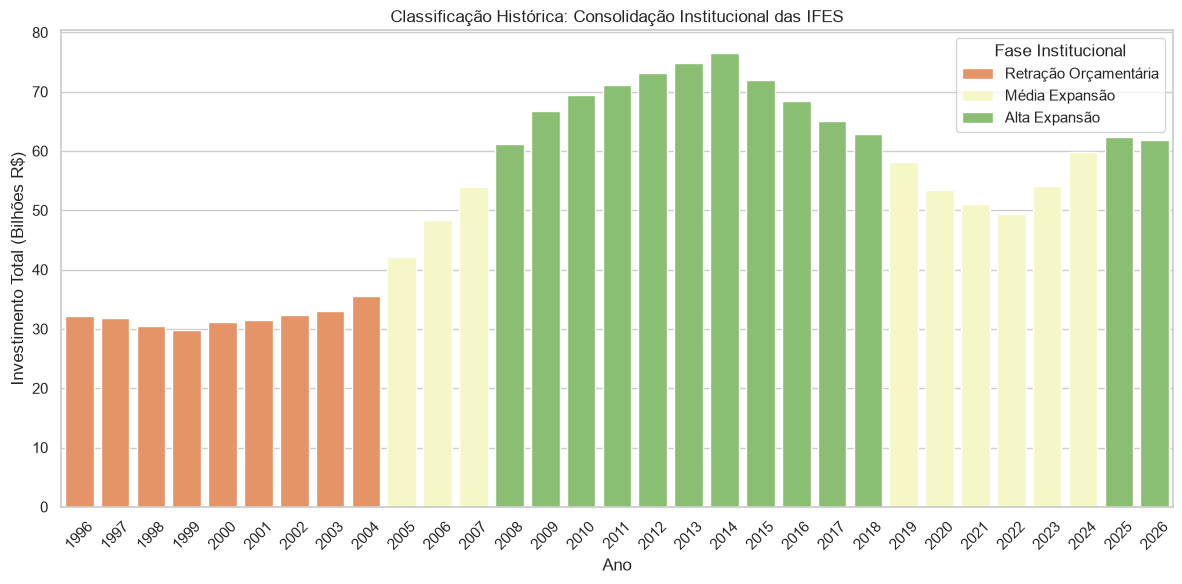

In [12]:

# 6. Métricas Customizadas via apply e Paletas de Cores

def classifica_ano(row):
    if row['investimento_total_ifes_bilhoes_brl'] > 60:
        return 'Alta Expansão'
    elif row['investimento_total_ifes_bilhoes_brl'] > 40:
        return 'Média Expansão'
    else:
        return 'Retração Orçamentária'

df['categoria_expansao'] = df.apply(classifica_ano, axis=1)

cat_order = ['Retração Orçamentária', 'Média Expansão', 'Alta Expansão']
paleta = sns.color_palette("RdYlGn", 3)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df, 
    x='ano', 
    y='investimento_total_ifes_bilhoes_brl', 
    hue='categoria_expansao',
    hue_order=cat_order,
    palette=paleta,
    dodge=False
)
plt.title('Classificação Histórica: Consolidação Institucional das IFES')
plt.xlabel('Ano')
plt.ylabel('Investimento Total (Bilhões R$)')
plt.xticks(rotation=45)
plt.legend(title='Fase Institucional')
plt.tight_layout()
plt.savefig('fig5_categorias.png', dpi=150)
plt.show()
plt.close()



### 6. Métricas Customizadas e Classificação de Expansão

* **O fato:** A categorização histórica mostra que as IFES viveram um longo e contínuo ciclo de "Alta Expansão" institucional de 2008 a 2015. Nos anos mais recentes, no entanto, o sistema apresenta um claro esgotamento dos aportes, retornando a uma realidade de "Média Expansão" e culminando no retorno à "Retração Orçamentária" ao final da série, que não era vista desde o início dos anos 2000.
* **O design:** Optou-se por um gráfico de barras para facilitar a percepção de volume financeiro acumulado ano a ano. Para mapear as categorias, aplicou-se a paleta de cores divergente `RdYlGn` (Vermelho-Amarelo-Verde). Esta paleta traduz o fenômeno político-econômico de forma semântica: verde transmite bonança e saúde financeira ("Alta Expansão"), tons amarelados indicam transição/atenção, e o vermelho alerta para a crise e corte ("Retração Orçamentária").